Character-level

In [55]:

from pathlib import Path
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,)


DATA_DIR = Path("../../data/raw/COLDataset/COLDataset")


# 2. 读取数据
train_df = pd.read_csv(DATA_DIR / "train.csv", encoding="utf-8-sig",)
dev_df = pd.read_csv(DATA_DIR / "dev.csv", encoding="utf-8-sig",)


# 3. 清理文本
# 缺失值填成空字符串（TF-IDF 不接受 NaN）   强制转字符串（防止某些行被读成数字或 float）  去掉首尾空白
for df in [train_df, dev_df]:
    df["TEXT"] = df["TEXT"].fillna("").astype(str).str.strip()


X_train = train_df["TEXT"]
y_train = train_df["label"]

X_dev = dev_df["TEXT"]
y_dev = dev_df["label"]

In [56]:
# =========================
## Character-level TF-IDF (2,5)
# =========================
# analyzer="char"：按字符切分，不用分词。这是处理中文最常用的省事做法，避免依赖 jieba 等分词器，也避免分词错误带来的噪声。
# ngram_range=(2, 5)：使用 2~5 个字符的连续组合（bigram 到 5-gram）。中文单字信息量低，字符 n-gram 能捕捉“地域黑”“女拳”这类短语级线索。
# min_df=2：某个字符 n-gram 至少在 2 个文档中出现才保留，过滤掉极罕见的噪声特征，缩小词表。
# sublinear_tf=True：词频用 1 + log(tf) 而不是原始 tf，抑制高频词过度主导，对长文本更稳。
vectorizer = TfidfVectorizer(analyzer="char", ngram_range=(2, 5), min_df=2, sublinear_tf=True,)

X_train_tfidf = vectorizer.fit_transform(X_train)  # 训练集：fit + transform
X_dev_tfidf = vectorizer.transform(X_dev)  # 验证/测试集：只 transform

print("TF-IDF feature shape:")
print("Train:", X_train_tfidf.shape)
print("Dev:  ", X_dev_tfidf.shape)



# 5. Logistic Regression
model = LogisticRegression(max_iter=2000, random_state=42)
model.fit(X_train_tfidf, y_train,)



# 6. Dev evaluation
dev_pred = model.predict(X_dev_tfidf)

print("\n" + "=" * 60)
print("DEV RESULT")
print("=" * 60)

print("Accuracy:", accuracy_score(y_dev, dev_pred),)
print("\nClassification Report:")
print(classification_report( y_dev, dev_pred, target_names=["Safe", "Offensive"],))

print("Confusion Matrix:")
print(confusion_matrix( y_dev, dev_pred,))

TF-IDF feature shape:
Train: (25726, 338474)
Dev:   (6431, 338474)

DEV RESULT
Accuracy: 0.8815114290157052

Classification Report:
              precision    recall  f1-score   support

        Safe       0.88      0.89      0.88      3220
   Offensive       0.89      0.88      0.88      3211

    accuracy                           0.88      6431
   macro avg       0.88      0.88      0.88      6431
weighted avg       0.88      0.88      0.88      6431

Confusion Matrix:
[[2855  365]
 [ 397 2814]]


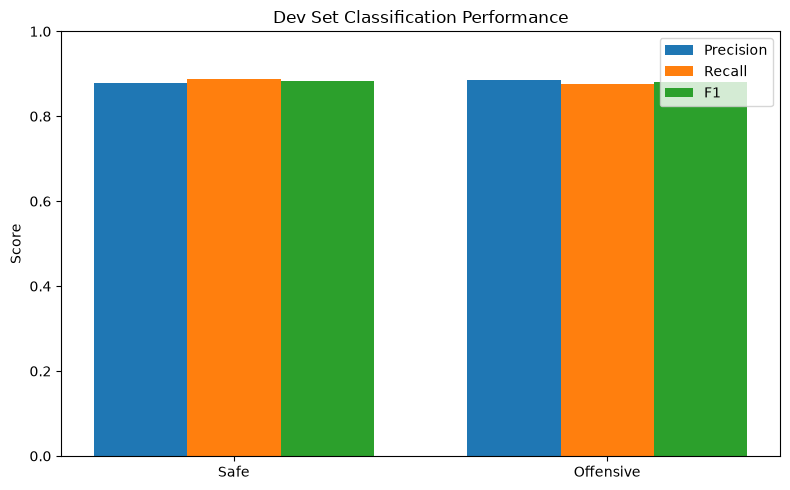

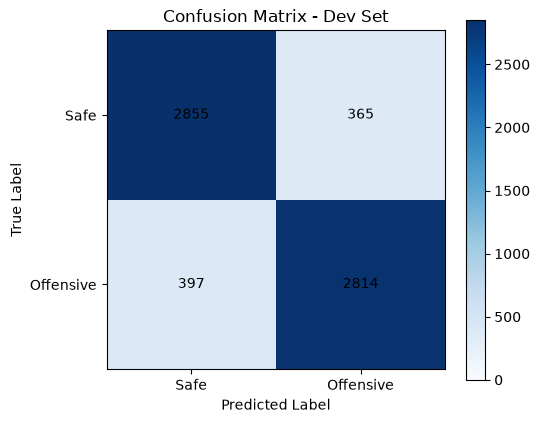

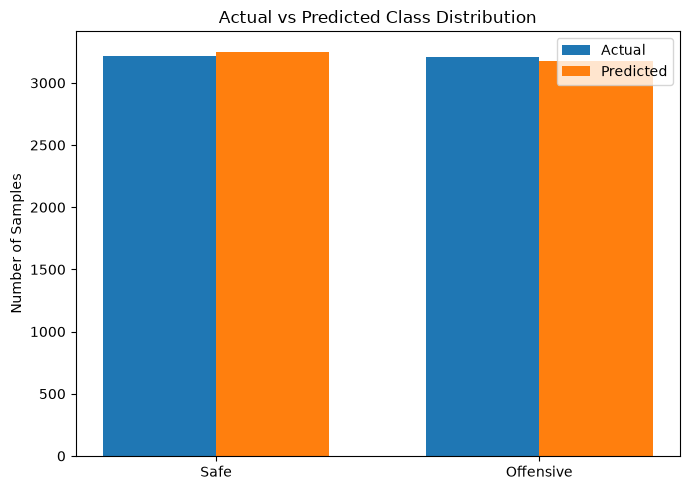

In [57]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, _ = precision_recall_fscore_support(y_dev, dev_pred, labels=[0, 1], zero_division=0,)
labels = ["Safe", "Offensive"]

x = range(len(labels))
width = 0.25

plt.figure(figsize=(8, 5))
plt.bar([i - width for i in x], precision, width=width, label="Precision",)
plt.bar(x, recall,  width=width, label="Recall",)
plt.bar([i + width for i in x], f1, width=width, label="F1",)

plt.xticks(x, labels)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Dev Set Classification Performance")
plt.legend()

plt.tight_layout()
plt.show()




import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_dev, dev_pred,)
labels = ["Safe", "Offensive"]
plt.figure(figsize=(5.5, 4.5))
plt.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max())

plt.xticks(range(len(labels)), labels,)
plt.yticks(range(len(labels)), labels,)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Dev Set")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center",)

plt.colorbar()

plt.tight_layout()
plt.show()




import matplotlib.pyplot as plt
import pandas as pd

actual_counts = pd.Series(y_dev).value_counts().sort_index()
predicted_counts = pd.Series(dev_pred).value_counts().sort_index()

labels = ["Safe", "Offensive"]
x = range(len(labels))
width = 0.35
plt.figure(figsize=(7, 5))
plt.bar([i - width / 2 for i in x],  actual_counts,  width=width, label="Actual",)
plt.bar([i + width / 2 for i in x],  predicted_counts,  width=width, label="Predicted",)

plt.xticks(x, labels)
plt.ylabel("Number of Samples")
plt.title("Actual vs Predicted Class Distribution")
plt.legend()

plt.tight_layout()
plt.show()

In [58]:
## Character-level TF-IDF (3,5)

# This experiment evaluates character n-grams with a range of 3 to 5.

In [59]:
# Character-level TF-IDF (3,5)

char35_vectorizer = TfidfVectorizer(analyzer="char", ngram_range=(3, 5), min_df=2, sublinear_tf=True)

X_train_char35 = char35_vectorizer.fit_transform(X_train)
X_dev_char35 = char35_vectorizer.transform(X_dev)

print("Train:", X_train_char35.shape)
print("Dev:", X_dev_char35.shape)


# Logistic Regression
char35_model = LogisticRegression(max_iter=2000, random_state=42)
char35_model.fit(X_train_char35, y_train)
char35_pred = char35_model.predict(X_dev_char35)


# Evaluation
print("CHAR (3,5) RESULT")
print(classification_report(y_dev, char35_pred, target_names=["Safe", "Offensive"],digits=4))

print("Confusion Matrix:")
print(confusion_matrix(y_dev, char35_pred))

Train: (25726, 256232)
Dev: (6431, 256232)
CHAR (3,5) RESULT
              precision    recall  f1-score   support

        Safe     0.8356    0.8584    0.8468      3220
   Offensive     0.8540    0.8306    0.8421      3211

    accuracy                         0.8445      6431
   macro avg     0.8448    0.8445    0.8445      6431
weighted avg     0.8448    0.8445    0.8445      6431

Confusion Matrix:
[[2764  456]
 [ 544 2667]]


Word-level

In [60]:
# python -m pip install jieba
import jieba
import re

def chinese_tokenizer(text):
    words = jieba.lcut(text)

    # 去除纯标点符号
    words = [ word.strip() for word in words  if re.search(r"[\u4e00-\u9fffA-Za-z0-9]", word)]
    return words

In [61]:
# analyzer="word"	按词语处理
# tokenizer	使用 jieba 分词
# token_pattern=None	禁用默认正则分词规则
# ngram_range=(1,2)	使用 unigram 和 bigram
# min_df=2	至少出现在两个文档中
# sublinear_tf=True	使用对数词频
word_vectorizer = TfidfVectorizer(analyzer="word", tokenizer=chinese_tokenizer,  token_pattern=None, 
                                  ngram_range=(1, 2), min_df=2, sublinear_tf=True,)


In [62]:
# Word-level TF-IDF

X_train_word = word_vectorizer.fit_transform(X_train)
X_dev_word = word_vectorizer.transform(X_dev)

print("Word TF-IDF feature shape:")
print("Train:", X_train_word.shape)
print("Dev:", X_dev_word.shape)


# Logistic Regression
word_model = LogisticRegression(max_iter=2000, random_state=42,)
word_model.fit(X_train_word, y_train)


# Validation prediction
word_pred = word_model.predict(X_dev_word)

# Evaluation
print("\nWORD-LEVEL TF-IDF RESULT")
print("Accuracy:", accuracy_score(y_dev, word_pred))
print(classification_report(y_dev, word_pred, target_names=["Safe", "Offensive"],))

print("Confusion Matrix:")
print(confusion_matrix(y_dev, word_pred))

Word TF-IDF feature shape:
Train: (25726, 79288)
Dev: (6431, 79288)

WORD-LEVEL TF-IDF RESULT
Accuracy: 0.8897527600684186
              precision    recall  f1-score   support

        Safe       0.89      0.89      0.89      3220
   Offensive       0.89      0.89      0.89      3211

    accuracy                           0.89      6431
   macro avg       0.89      0.89      0.89      6431
weighted avg       0.89      0.89      0.89      6431

Confusion Matrix:
[[2878  342]
 [ 367 2844]]


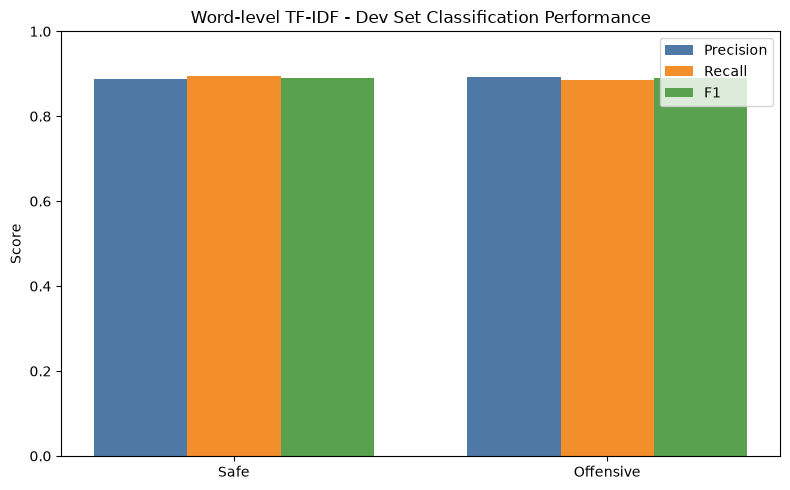

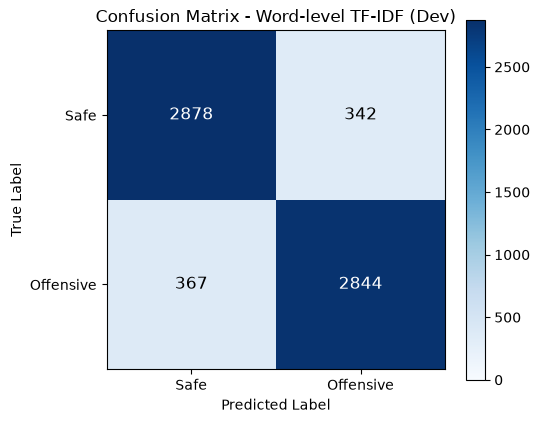

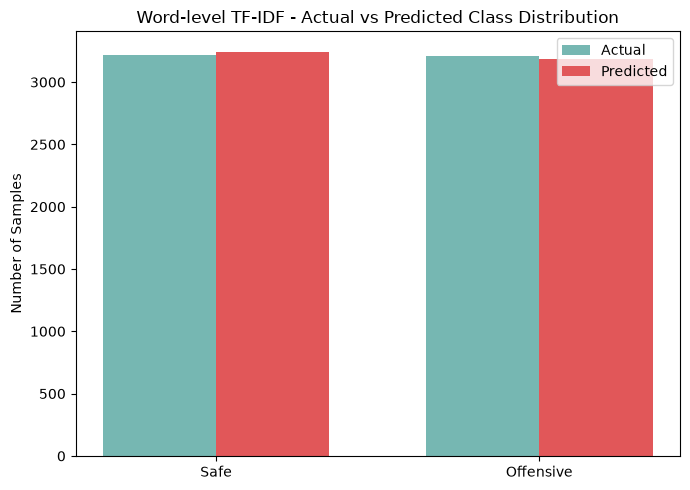

In [63]:

labels = ["Safe", "Offensive"]

# =====================================
# Plot 1: Precision / Recall / F1
# =====================================
precision, recall, f1, _ = precision_recall_fscore_support(
    y_dev, word_pred, labels=[0, 1], zero_division=0
)

x = range(len(labels))
width = 0.25

plt.figure(figsize=(8, 5))
plt.bar([i - width for i in x], precision, width=width, label="Precision", color="#4E79A7")
plt.bar(x, recall, width=width, label="Recall", color="#F28E2B")
plt.bar([i + width for i in x], f1, width=width, label="F1", color="#59A14F")

plt.xticks(x, labels)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Word-level TF-IDF - Dev Set Classification Performance")
plt.legend()

plt.tight_layout()
plt.show()





# Plot 2: Confusion Matrix
cm = confusion_matrix(y_dev, word_pred)

plt.figure(figsize=(5.5, 4.5))
plt.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max())

plt.xticks(range(len(labels)), labels)
plt.yticks(range(len(labels)), labels)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Word-level TF-IDF (Dev)")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ratio = cm[i, j] / cm.max() if cm.max() else 0
        plt.text(
            j, i, cm[i, j],
            ha="center", va="center",
            color="white" if ratio > 0.55 else "black", fontsize=12,)

plt.colorbar()
plt.tight_layout()
plt.show()



# Plot 3: Actual vs Predicted Distribution
actual_counts = pd.Series(y_dev).value_counts().sort_index()
predicted_counts = pd.Series(word_pred).value_counts().sort_index()

x = range(len(labels))
width = 0.35

plt.figure(figsize=(7, 5))
plt.bar([i - width / 2 for i in x], actual_counts, width=width, label="Actual", color="#76B7B2")
plt.bar([i + width / 2 for i in x], predicted_counts, width=width, label="Predicted", color="#E15759")

plt.xticks(x, labels)
plt.ylabel("Number of Samples")
plt.title("Word-level TF-IDF - Actual vs Predicted Class Distribution")
plt.legend()

plt.tight_layout()
plt.show()



# Feature Fusion：特征融合

Character + Word Feature Fusion

Combining character-level and word-level TF-IDF features for comment classification.

In [64]:
from scipy.sparse import hstack


# 1. Combine Character and Word Features
X_train_fusion = hstack([X_train_tfidf, X_train_word], format="csr")
X_dev_fusion = hstack([X_dev_tfidf, X_dev_word], format="csr")


# 2. Check Feature Dimensions
print("Feature Fusion:")
print("Train:", X_train_fusion.shape)
print("Dev:", X_dev_fusion.shape)

Feature Fusion:
Train: (25726, 417762)
Dev: (6431, 417762)


In [65]:
# 3. Train Fusion Model
fusion_model = LogisticRegression(max_iter=2000, random_state=42)
fusion_model.fit(X_train_fusion, y_train)


# 4. Validation Prediction
fusion_pred = fusion_model.predict(X_dev_fusion)

# 5. Evaluation
print("CHARACTER + WORD TF-IDF RESULT")
print("Accuracy:", accuracy_score(y_dev, fusion_pred))

print("\nClassification Report:")
print(classification_report(y_dev, fusion_pred, target_names=["Safe", "Offensive"], digits=4))

print("Confusion Matrix:")
print(confusion_matrix(y_dev, fusion_pred))

CHARACTER + WORD TF-IDF RESULT
Accuracy: 0.8993935624319701

Classification Report:
              precision    recall  f1-score   support

        Safe     0.8999    0.8991    0.8995      3220
   Offensive     0.8989    0.8997    0.8993      3211

    accuracy                         0.8994      6431
   macro avg     0.8994    0.8994    0.8994      6431
weighted avg     0.8994    0.8994    0.8994      6431

Confusion Matrix:
[[2895  325]
 [ 322 2889]]


## Two-stage Moderation

### Stage 1: Confidence-based Routing

Use the predicted probability of the Fusion model
to determine whether a comment should be:

- Automatically allowed
- Automatically blocked
- Sent to LLM for further review

In [66]:
# 1. Get Prediction Probabilities
fusion_prob = fusion_model.predict_proba(X_dev_fusion)

# 获取 Offensive 类别的概率
offensive_prob = fusion_prob[:, 1]


# 2. Create Probability DataFrame
prob_df = pd.DataFrame({"text": X_dev.reset_index(drop=True),  "true_label": y_dev.reset_index(drop=True),  "offensive_probability": offensive_prob})
prob_df["true_name"] = prob_df["true_label"].map({0: "Safe", 1: "Offensive"})


# 3. Inspect Probability Distribution
print("Probability Distribution:")
display(prob_df.groupby("true_name")["offensive_probability"].describe().round(4))

Probability Distribution:


,count,mean,std,min,25%,50%,75%,max
true_name,,,,,,,,
Offensive,3211.0,0.7872,0.1982,0.0152,0.6961,0.8520,0.9388,1.0000
Safe,3220.0,0.2270,0.1943,0.0035,0.0867,0.1664,0.3115,0.9959


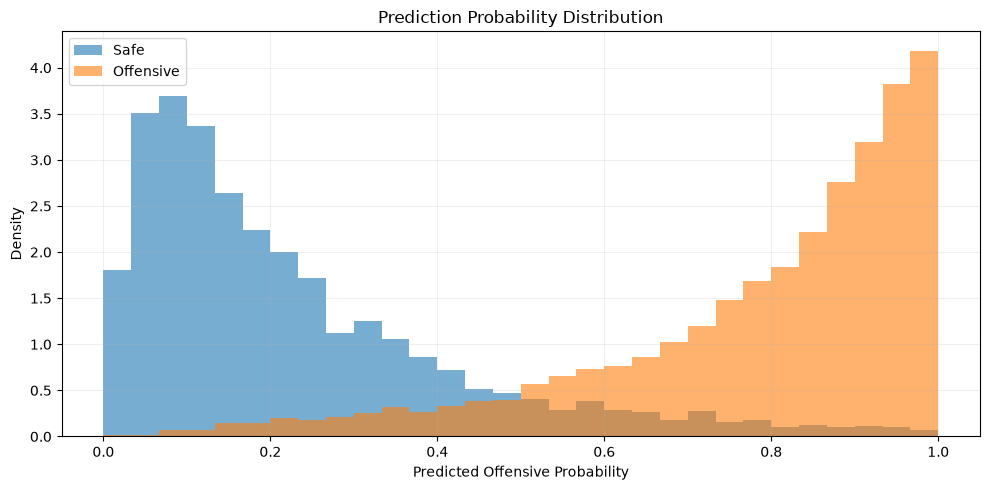

In [67]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 5))
plt.hist(
    prob_df.loc[prob_df["true_label"] == 0, "offensive_probability"],
    bins=np.linspace(0, 1, 31), alpha=0.6,
    label="Safe", density=True
)

plt.hist(
    prob_df.loc[prob_df["true_label"] == 1, "offensive_probability"],
    bins=np.linspace(0, 1, 31), alpha=0.6,
    label="Offensive", density=True
)

plt.xlabel("Predicted Offensive Probability")
plt.ylabel("Density")
plt.title("Prediction Probability Distribution")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

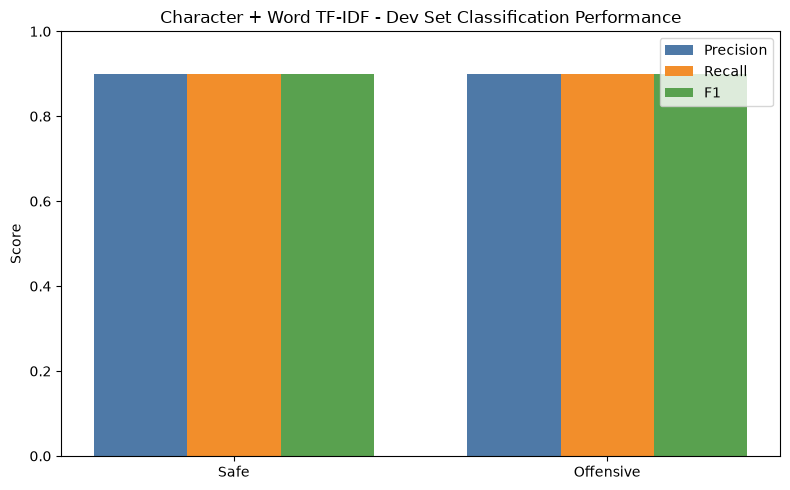

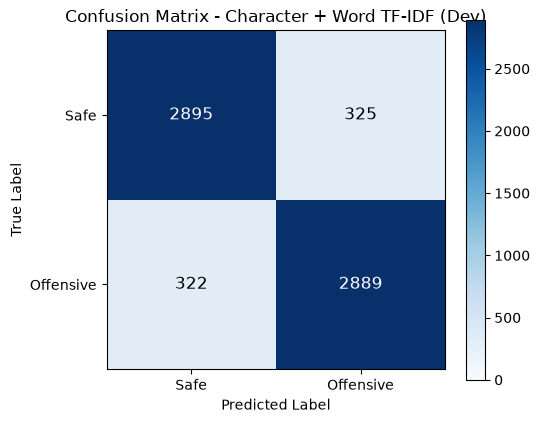

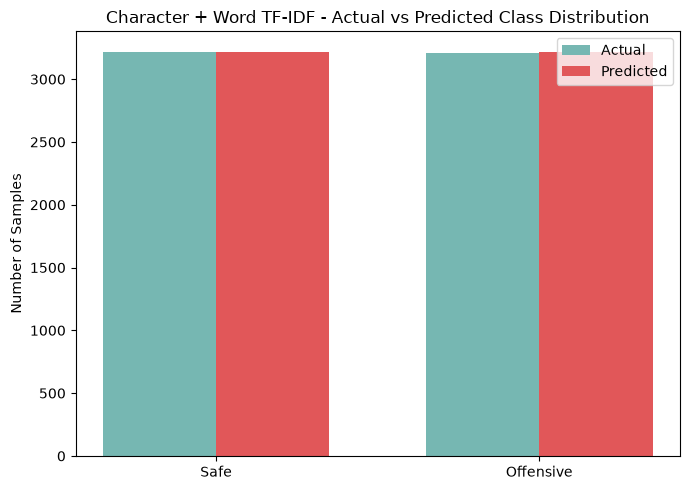

In [68]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (precision_recall_fscore_support, confusion_matrix,)

labels = ["Safe", "Offensive"]

# =====================================
# Plot 1: Precision / Recall / F1
precision, recall, f1, _ = precision_recall_fscore_support(y_dev, fusion_pred, labels=[0, 1], zero_division=0)
x = range(len(labels))
width = 0.25

plt.figure(figsize=(8, 5))
plt.bar([i - width for i in x], precision, width=width, label="Precision", color="#4E79A7")
plt.bar(x, recall, width=width, label="Recall", color="#F28E2B")
plt.bar([i + width for i in x], f1, width=width, label="F1", color="#59A14F")

plt.xticks(x, labels)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Character + Word TF-IDF - Dev Set Classification Performance")
plt.legend()

plt.tight_layout()
plt.show()


# =====================================
# Plot 2: Confusion Matrix
cm = confusion_matrix(y_dev, fusion_pred)
plt.figure(figsize=(5.5, 4.5))
plt.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max())
plt.xticks(range(len(labels)), labels)
plt.yticks(range(len(labels)), labels)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Character + Word TF-IDF (Dev)")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ratio = cm[i, j] / cm.max() if cm.max() else 0
        plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if ratio > 0.55 else "black", fontsize=12,)

plt.colorbar()
plt.tight_layout()
plt.show()


# =====================================
# Plot 3: Actual vs Predicted Distribution
actual_counts = pd.Series(y_dev).value_counts().sort_index()
predicted_counts = pd.Series(fusion_pred).value_counts().sort_index()

x = range(len(labels))
width = 0.35

plt.figure(figsize=(7, 5))
plt.bar([i - width / 2 for i in x], actual_counts, width=width, label="Actual", color="#76B7B2")
plt.bar([i + width / 2 for i in x], predicted_counts, width=width, label="Predicted", color="#E15759")

plt.xticks(x, labels)
plt.ylabel("Number of Samples")
plt.title("Character + Word TF-IDF - Actual vs Predicted Class Distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [69]:
from sklearn.metrics import precision_recall_fscore_support

def evaluate_model(name, predictions):
    precision, recall, f1, _ = precision_recall_fscore_support(y_dev, predictions, labels=[0, 1], zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_dev, predictions, labels=[0, 1]).ravel()

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_dev, predictions),
        "Macro F1": f1.mean(),
        "Offensive Precision": precision[1],
        "Offensive Recall": recall[1],
        "False Positive": fp,
        "False Negative": fn
    }


comparison = pd.DataFrame([
    evaluate_model("Character (2,5)", dev_pred),
    evaluate_model("Word (1,2)", word_pred),
    evaluate_model("Character + Word", fusion_pred)
])
print(comparison.to_string(index=False))

           Model  Accuracy  Macro F1  Offensive Precision  Offensive Recall  False Positive  False Negative
 Character (2,5)  0.881511  0.881507             0.885184          0.876363             365             397
      Word (1,2)  0.889753  0.889750             0.892655          0.885705             342             367
Character + Word  0.899394  0.899393             0.898880          0.899720             325             322


In [70]:
# Error Analysis - Feature Fusion
error_df = pd.DataFrame({
    "text": X_dev.reset_index(drop=True),
    "true_label": y_dev.reset_index(drop=True),
    "pred_label": pd.Series(fusion_pred)
})

# 标签转换
label_names = {0: "Safe",  1: "Offensive"}
error_df["true_name"] = error_df["true_label"].map(label_names)
error_df["pred_name"] = error_df["pred_label"].map(label_names)

# 区分两种错误
error_df["error_type"] = ""
error_df.loc[(error_df["true_label"] == 0) & (error_df["pred_label"] == 1), "error_type"] = "False Positive"
error_df.loc[(error_df["true_label"] == 1) & (error_df["pred_label"] == 0), "error_type"] = "False Negative"


# 提取错误样本
fp_errors = error_df[error_df["error_type"] == "False Positive"]
fn_errors = error_df[error_df["error_type"] == "False Negative"]

print("Total errors:", len(fp_errors) + len(fn_errors))
print("False Positive:", len(fp_errors))
print("False Negative:", len(fn_errors))

Total errors: 647
False Positive: 325
False Negative: 322


In [71]:
# Display Misclassified Comments

pd.set_option("display.max_colwidth", 300)
print("'\n'FALSE POSITIVE - Safe predicted as Offensive")
display(fp_errors[["text", "true_name", "pred_name"]].sample(n=min(20, len(fp_errors)), random_state=42))


print("\n" + "=" * 70)
print("FALSE NEGATIVE - Offensive predicted as Safe")
display(fn_errors[["text", "true_name", "pred_name"]].sample(n=min(20, len(fn_errors)), random_state=42))

'
'FALSE POSITIVE - Safe predicted as Offensive


,text,true_name,pred_name
4882,本人山东妹子嫁给上海男人，跟你反过来了。上海男人确实很好，顾家疼老婆，我公婆也特别好，不会歧视外地人。只是我不懂，你为什么连山东两个字都要故意打错？你怎么不打错青岛两个字？,Safe,Offensive
2299,那个 我想说不是所有东北人都这样的(๑￣ ￣๑),Safe,Offensive
5140,没想到时至今日，在这里依然能看到地图炮。。。河南人路过，现居西安，本人表示从来没偷过井盖，对井盖也没有兴趣，也没见过有人去偷井盖。,Safe,Offensive
263,男尊女卑在过去被推崇那不就是因为过去社会看重的是人的体能，而不是因为你想的中国就是个重男轻女的国家，社会需要什么不会因为这个人是男的女的，而是因为这个人具备什么特质。团结你的朋友抗击共同的敌人,Safe,Offensive
1881,我倒是觉得引进黑人没什么问题，中国文化和美国文化本质不同，黑人在中国教育环境下能变成中华黑人，有思想有内涵，再加上黑人能生，黑人和中国女性的结合会十分完美，保留了中华血统的同时还优化了运动基因，,Safe,Offensive
4693,不是说广东人什么都吃吗？明显辣椒不吃啊！,Safe,Offensive
5665,吴芝圃可被河南人民斗死了。,Safe,Offensive
4118,有见地，就像生活中拯救自卑者的方法，如果是一味地保护，鼓励，而非从根本上平等对待他，那么同样是一种歧视。电影里的“反派角色”就像日常工作中的重要职位，只有对“白人”和“黑人”一视同仁，都可做这个反面人设，才是真正的公平。支持。,Safe,Offensive
4230,不要把外地小妹妹吓着呢，以后没人敢嫁到重庆来了,Safe,Offensive
1971,愿美国黑人独立，愿中国黑人去美国黑人独立区享受自由生活,Safe,Offensive



FALSE NEGATIVE - Offensive predicted as Safe


,text,true_name,pred_name
3970,我们东北天天睡炕上，我们东北顿顿吃酸菜，我们东北半个月洗次澡。不穿貂好像对不起你家祖宗:),Offensive,Safe
3224,最近很喜欢看女同，看的时候代入感很强，希望自己也是个女生和女生爱爱。,Offensive,Safe
4486,不是黄女受欢迎，而是黄女对比白女的性格属于千依百顺，而且容易泡，亚裔女崇洋媚外的多，受到底层外国男人喜欢，你看看好莱坞明星，nba黑人球员，除了那个破产的凯奇，谁找黄女，不都是白女，NBA黑人有钱都找白女，黄女无人问津。,Offensive,Safe
271,一个朋友，得知其宿舍之前住了个印度人，感到非常恶心，用大量消毒剂打扫房间两天。如果真的有味道，消毒没啥问题吧一个学妹，交了个印度男朋友。其他同学得知此事，背后指责她好贱。这个确实是，,Offensive,Safe
2491,确切点儿说，是不是女生的价值不需要通过媚人来体现？,Offensive,Safe
2958,北方。“我来自北京。”回。“冬天冷死了吧？”,Offensive,Safe
5469,好像可以称呼其小哥哥（爷T）。,Offensive,Safe
3768,看看抖音男性对彩礼的评论:我未来承包了你的后半生，我没找你要抚养费都不错了，你还敢要彩礼？,Offensive,Safe
4841,醒醒，你哪来的女朋友？工头叫你搬砖了！,Offensive,Safe
6257,还有BP一部分粉丝真的无语 微博啥的好多都看不起东南亚粉丝不承认他们的 东南亚人民心里苦啊连粉丝也分国籍了[飙泪笑],Offensive,Safe


Testing

Test Dataset: (5323, 6)

Label Distribution:
label
0    3216
1    2107
Name: count, dtype: int64

Feature Shapes:
Character: (5323, 338474)
Word: (5323, 79288)
Fusion: (5323, 417762)

CHARACTER + WORD TF-IDF - TEST RESULT
Accuracy: 0.7952

Classification Report:
              precision    recall  f1-score   support

        Safe     0.8655    0.7826    0.8220      3216
   Offensive     0.7106    0.8144    0.7590      2107

    accuracy                         0.7952      5323
   macro avg     0.7881    0.7985    0.7905      5323
weighted avg     0.8042    0.7952    0.7971      5323

Confusion Matrix:
[[2517  699]
 [ 391 1716]]


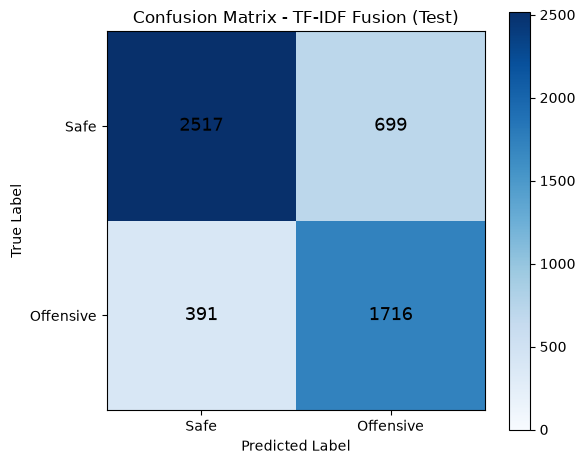


Test predictions saved!
error_type
Correct           4233
False Positive     699
False Negative     391
Name: count, dtype: int64


In [72]:
# Character + Word TF-IDF
# Final Test Evaluation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import hstack
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support)


# 1. Load Test Dataset
test_df = pd.read_csv(DATA_DIR / "test.csv", encoding="utf-8-sig")
test_df["TEXT"] = (test_df["TEXT"].fillna("").astype(str).str.strip())

X_test = test_df["TEXT"]
y_test = test_df["label"].astype(int)

print("Test Dataset:", test_df.shape)
print("\nLabel Distribution:")
print(y_test.value_counts())



# 2. Transform Test Data
X_test_char = vectorizer.transform(X_test)  # Character-level TF-IDF
X_test_word = word_vectorizer.transform(X_test)  # Word-level TF-IDF

# Feature Fusion
X_test_fusion = hstack([X_test_char, X_test_word], format="csr")

print("\nFeature Shapes:")
print("Character:", X_test_char.shape)
print("Word:", X_test_word.shape)
print("Fusion:", X_test_fusion.shape)


# 3. Predict
fusion_test_pred = fusion_model.predict(X_test_fusion)
fusion_test_prob = fusion_model.predict_proba(X_test_fusion)[:, list(fusion_model.classes_).index(1)]


# 4. Evaluation
print("\n" + "=" * 60)
print("CHARACTER + WORD TF-IDF - TEST RESULT")
print("=" * 60)

print("Accuracy:", round(accuracy_score(y_test, fusion_test_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, fusion_test_pred, target_names=["Safe", "Offensive"], digits=4))

cm = confusion_matrix(y_test, fusion_test_pred, labels=[0, 1])
print("Confusion Matrix:")
print(cm)



# 5. Plot Confusion Matrix
labels = ["Safe", "Offensive"]
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max())
plt.xticks(range(2), labels)
plt.yticks(range(2), labels)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - TF-IDF Fusion (Test)")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=13)
plt.colorbar()
plt.tight_layout()
plt.show()



# 6. Save Test Predictions
prediction_df = pd.DataFrame({
    "text": X_test.reset_index(drop=True),
    "true_label": y_test.reset_index(drop=True),
    "predicted_label": fusion_test_pred,
    "offensive_probability": fusion_test_prob
})

prediction_df["error_type"] = np.select(
    [
        (prediction_df["true_label"] == 0) & (prediction_df["predicted_label"] == 1),
        (prediction_df["true_label"] == 1) & (prediction_df["predicted_label"] == 0)
    ],
    ["False Positive", "False Negative"],
    default="Correct"
)

from pathlib import Path
PROJECT_ROOT = DATA_DIR.resolve().parents[3]
RESULT_DIR = PROJECT_ROOT / "results"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

prediction_df.to_csv(RESULT_DIR / "tfidf_fusion_test_predictions.csv",  index=False, encoding="utf-8-sig")
print("\nTest predictions saved!")
print(prediction_df["error_type"].value_counts())


In [73]:
import numpy as np
import pandas as pd

# 使用 Dev 数据，不使用 Test 数据调参
dev_prob = fusion_model.predict_proba(X_dev_fusion)[:, list(fusion_model.classes_).index(1)]
dev_true = np.asarray(y_dev)

results = []

for allow_threshold in np.arange(0, 0.51, 0.01):
    for block_threshold in np.arange(0.50, 1.01, 0.01):
        if allow_threshold >= block_threshold:
            continue

        allow_mask = dev_prob <= allow_threshold
        block_mask = dev_prob >= block_threshold

        # 避免样本过少导致 Precision 虚高
        if allow_mask.sum() < 30 or block_mask.sum() < 30:
            continue

        allow_precision = np.mean(dev_true[allow_mask] == 0)
        block_precision = np.mean(dev_true[block_mask] == 1)

        auto_count = allow_mask.sum() + block_mask.sum()

        results.append({
            "Allow Threshold": allow_threshold,
            "Block Threshold": block_threshold,
            "Allow Precision": allow_precision,
            "Block Precision": block_precision,
            "Auto Allow": allow_mask.sum(),
            "Auto Block": block_mask.sum(),
            "LLM Review": len(dev_true) - auto_count,
            "Auto Coverage": auto_count / len(dev_true)
        })

result_df = pd.DataFrame(results)

# 两种自动处理都要求至少 99% Precision
qualified = result_df[(result_df["Allow Precision"] >= 0.99) & (result_df["Block Precision"] >= 0.99)]

if qualified.empty:
    print("No threshold combination satisfies both 99% precision targets.")
else:
    display(qualified.sort_values("Auto Coverage", ascending=False).head(15).round(4))

No threshold combination satisfies both 99% precision targets.
